# Python DA Assignment 2 - Data Visualization

## 1) Loading the Taxis Dataset

In [8]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

# Display first five rows
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## 2) Handling Missing Values

In [10]:
# Check the number of rows and columns
df.shape

(6433, 14)

In [11]:
# Check column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [12]:
# Get statistical summary
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223,2019-03-16 08:45:49.491216,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


**Check missing values in each column**

In [13]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [14]:
# Fill missing payment values with mode
df['payment']=df['payment'].fillna(df['payment'].mode()[0])

In [15]:
# Check missing values again
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment             0
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [19]:
# Remove rows with missing location information because filling them with the most common location could give misleading visualizations.

df.dropna(subset=['pickup_zone','dropoff_zone','pickup_borough','dropoff_borough'],inplace=True)

In [20]:
# Check missing values again
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [21]:
df.shape

(6383, 14)

### 3) Visualizations using Matplotlib/Pandas Plot:

**★ Line Chart**

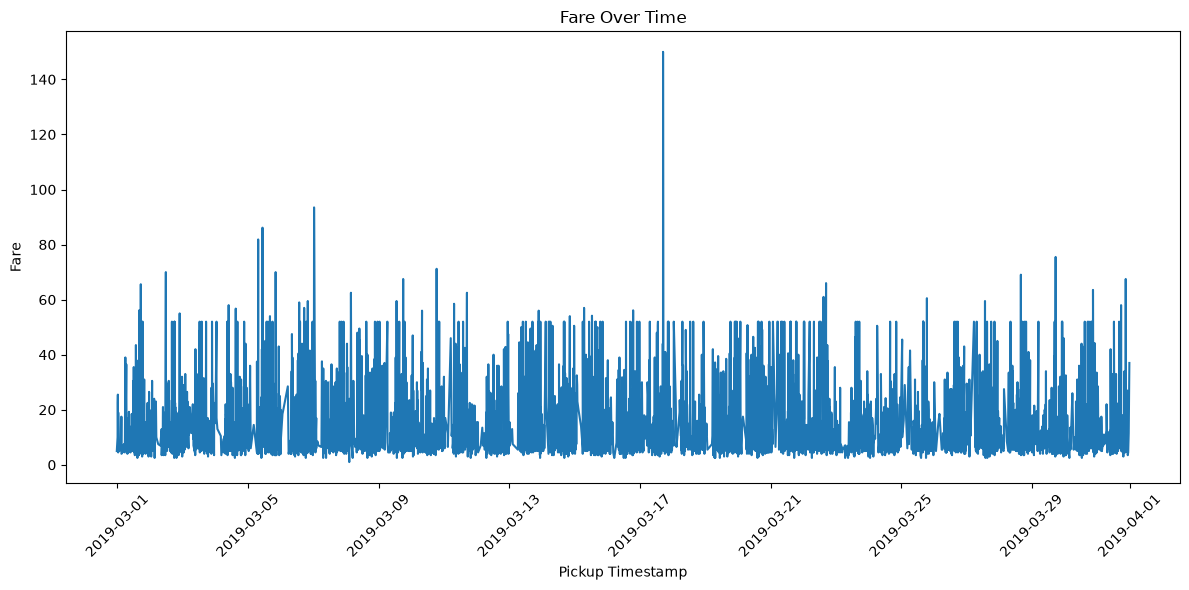

In [23]:
# Convert pickup column into datetime format
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data according to pickup time
df_sorted = df.sort_values("pickup")

plt.figure(figsize=(12, 6))
plt.plot(df_sorted["pickup"], df_sorted["fare"], label="Fare")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.title("Fare Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**★ Bar Chart**

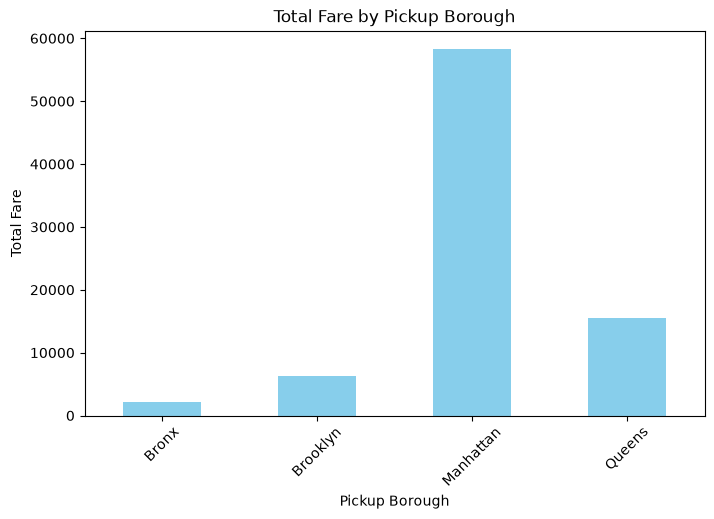

In [25]:
# Group by pickup borough and calculate total fare
borough_fare = df.groupby("pickup_borough")["fare"].sum()

plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar", color="skyblue")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total Fare by Pickup Borough")

plt.xticks(rotation=45)
plt.show()

**★ Pie Chart**

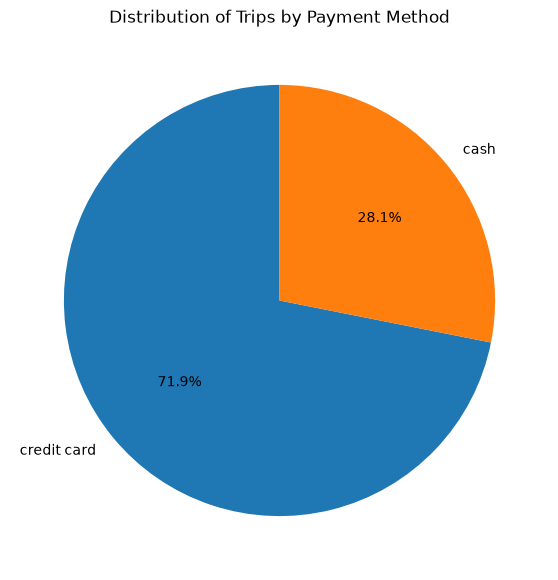

In [26]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Trips by Payment Method')
plt.show()

**★ Histogram**

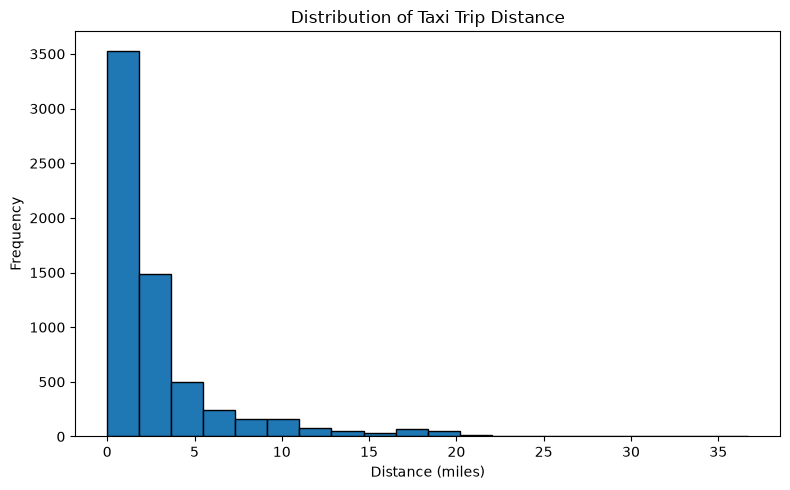

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(df['distance'], bins=20, edgecolor='black')

plt.xlabel('Distance (miles)')
plt.ylabel('Frequency')
plt.title('Distribution of Taxi Trip Distance')

plt.tight_layout()
plt.show()

**★ Box Plot**

<Figure size 900x500 with 0 Axes>

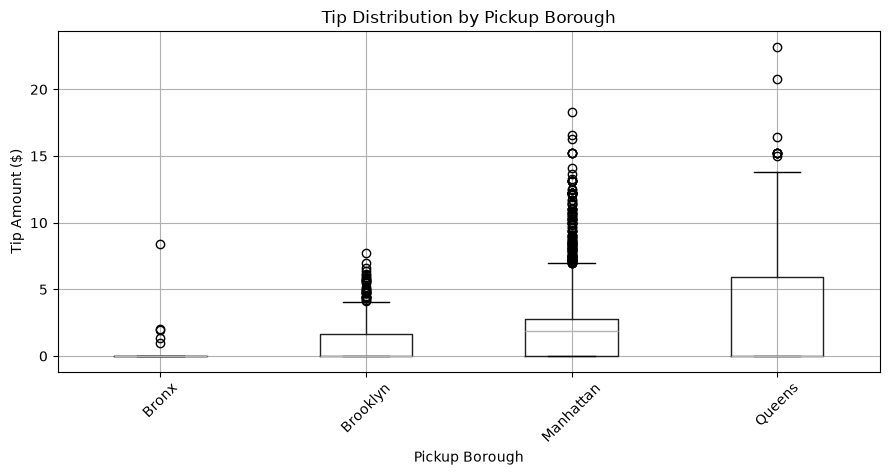

In [28]:
plt.figure(figsize=(9, 5))

df.boxplot(
    column='tip',
    by='pickup_borough',
    figsize=(9, 5)
)

plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount ($)')
plt.title('Tip Distribution by Pickup Borough')

plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Visualizations using Seaborn:

**★ Count Plot**

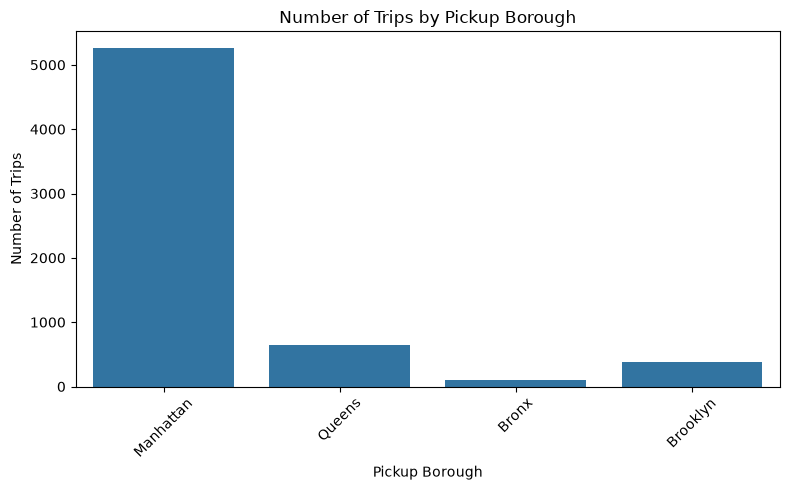

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='pickup_borough')

plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by Pickup Borough')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**★ Scatter Plot**

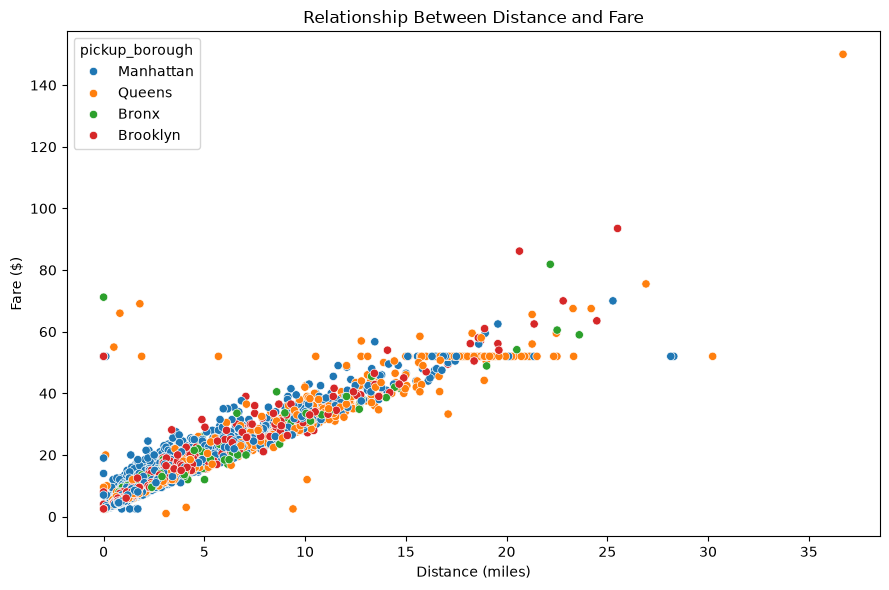

In [30]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough'
)

plt.xlabel('Distance (miles)')
plt.ylabel('Fare ($)')
plt.title('Relationship Between Distance and Fare')

plt.tight_layout()
plt.show()

**★ Heatmap**

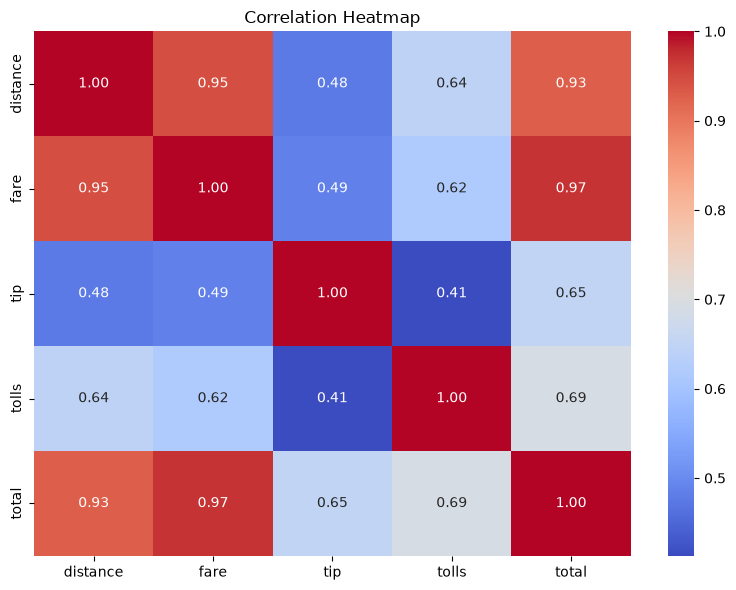

In [32]:
# Select numerical columns
numeric_df = df[['distance', 'fare', 'tip', 'tolls', 'total']]

# Calculate correlation matrix
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

**★ Pair Plot**

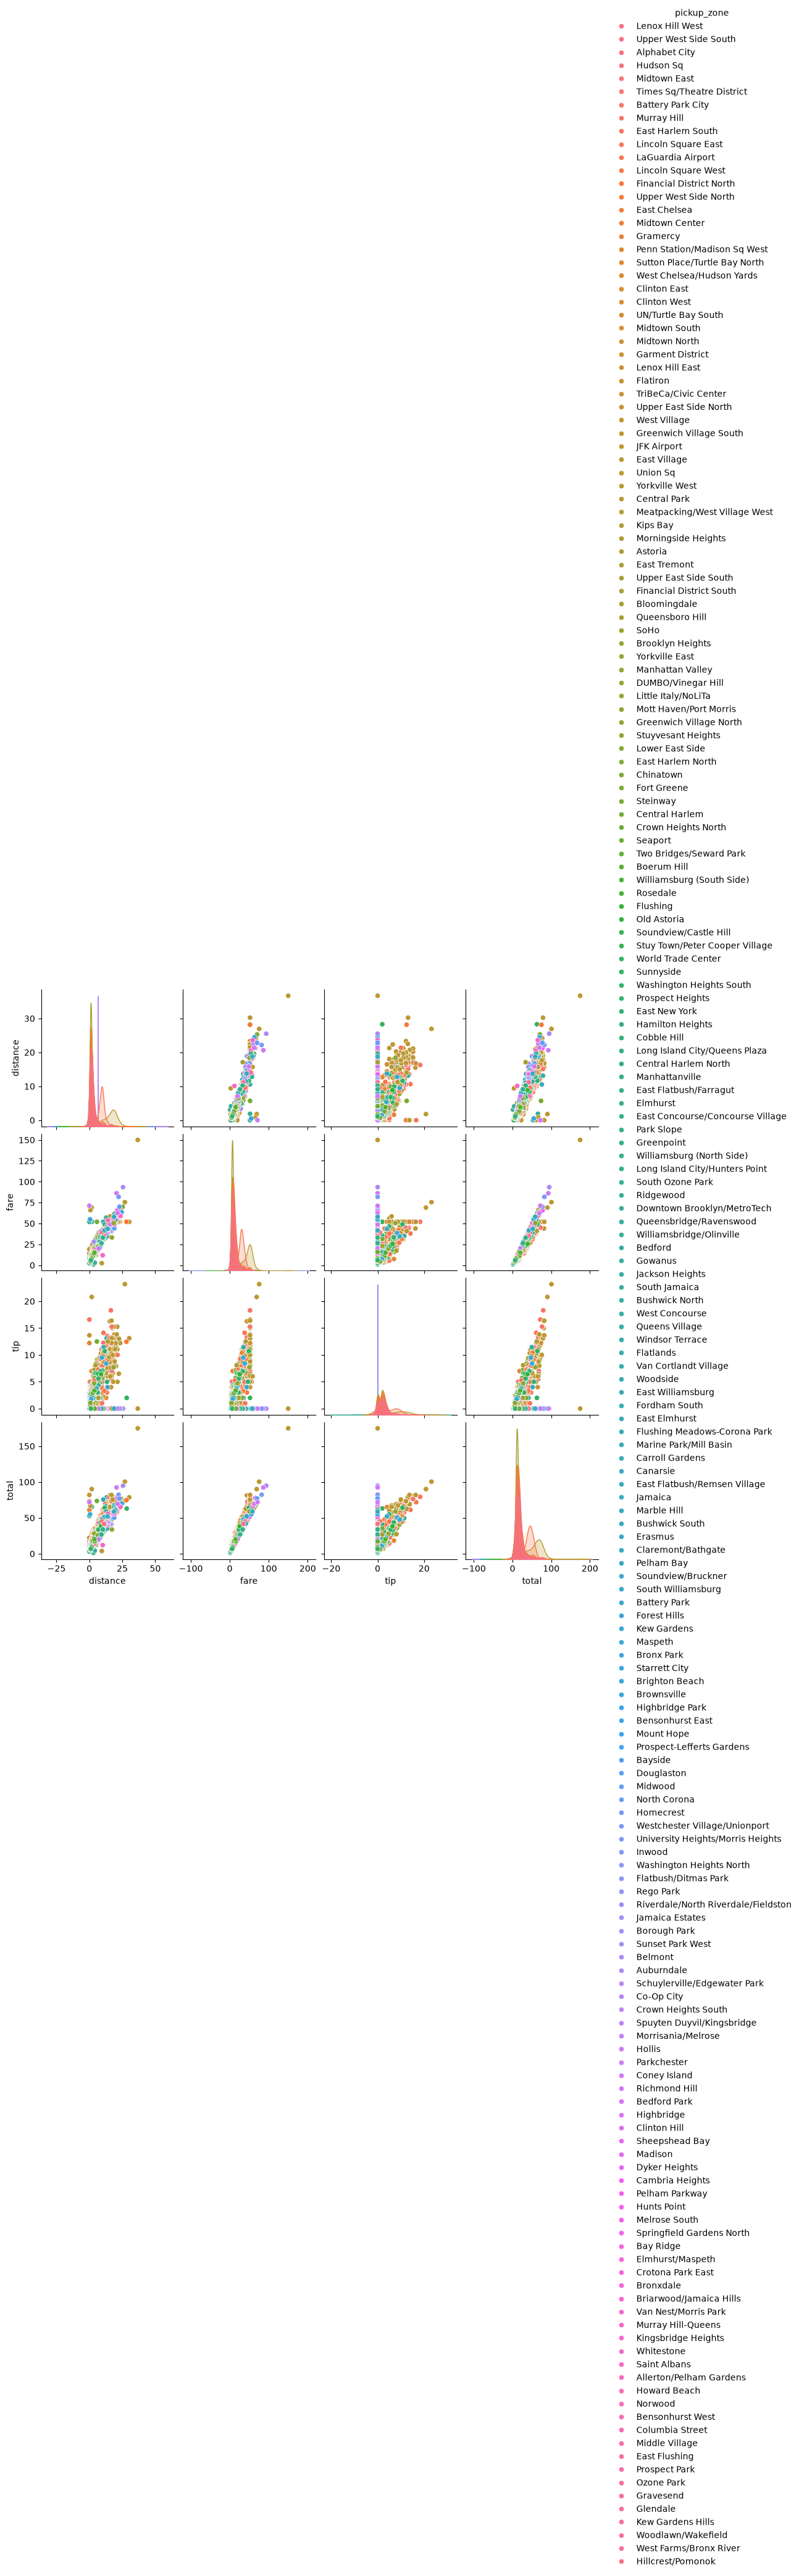

In [33]:
# Select required columns
pair_df = df[['distance', 'fare', 'tip', 'total', 'pickup_zone']].dropna()

# Create pair plot
sns.pairplot(
    pair_df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone'
)

plt.show()

**★ Violin Plot**

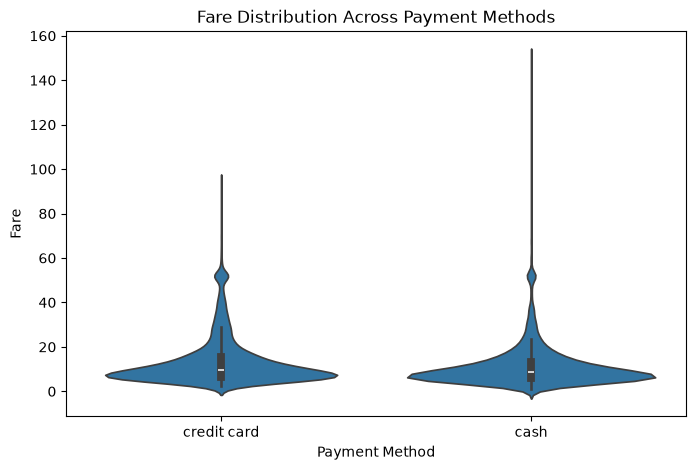

In [34]:
plt.figure(figsize=(8, 5))
sns.violinplot(x="payment", y="fare", data=df)
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.title("Fare Distribution Across Payment Methods")
plt.show()